In [109]:
"""
S = PERSONAS QUE PUEDEN INFECTARSE
E = PERSONAS EXPUESTAS QUE HAN SIDO EXPUESTAS, PERO NO SON INFECCIOSAS, PERIODO DE ENCUBACION
I = PERSONAS QUE YA SON CONTAGIOSAS
R = PERSONAS QUE YA NO SON CONTAGIOSAS, YA SEA POR RECUPERACION O MUERTE
BETA = PROBABILIDAD DE TRANSMISION DEL VIRUS
SIGMA = TASA DE INCUBACION 1/NUMERO DE DIAS EN INCUBACION
GAMMA = TASA DE RECUPERACION 1/NUMERO DE DIAS DE RECUPERACION (PERIODO INFECCIOSO)
"""

'\nS = PERSONAS QUE PUEDEN INFECTARSE\nE = PERSONAS EXPUESTAS QUE HAN SIDO EXPUESTAS, PERO NO SON INFECCIOSAS, PERIODO DE ENCUBACION\nI = PERSONAS QUE YA SON CONTAGIOSAS\nR = PERSONAS QUE YA NO SON CONTAGIOSAS, YA SEA POR RECUPERACION O MUERTE\nBETA = PROBABILIDAD DE TRANSMISION DEL VIRUS\nSIGMA = TASA DE INCUBACION 1/NUMERO DE DIAS EN INCUBACION\nGAMMA = TASA DE RECUPERACION 1/NUMERO DE DIAS DE RECUPERACION (PERIODO INFECCIOSO)\n'

In [110]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

In [111]:
N = 100000 # POBLACION TOTAL
I0 = 1 # PERSONAS INFECTADAS INICIALES
E0 = 0 # PERSONAS EXPUESTAS INICIALES
R0 = 0 # PERSONAS RECUPERADAS INICIALES
S0 = N - I0 - E0 - R0 # PERSONAS SUSCEPTIBLES INICIALES
beta = 0.4 # TASA DE TRANSMISION
sigma = 1/5 # TASA DE INCUBACION (1/NUMERO DE DIAS EN INCUBACION)
gamma = 1/10 # TASA DE RECUPERACION (1/
dias = 180



In [112]:
def seir_model(y, t, N, beta, sigma, gamma):
    S, E, I, R = y

    dSdt = -beta * S * I / N
    dEdt = beta * S * I / N - sigma * E
    dIdt = sigma * E - gamma * I
    dRdt = gamma * I

    return [dSdt, dEdt, dIdt, dRdt]

#vector de tiempo
t = np.linspace(0, dias, dias)

#Condiciones iniciales
y0 = [S0, E0, I0, R0]

In [113]:
solution = odeint(seir_model, y0, t, args=(N, beta, sigma, gamma))

In [114]:
#Extraer resultados
S,E,I,R = solution.T

In [115]:
#Determinar el maximo dia de infectados y cuantos?
dia_max_infectados_seir = np.argmax(I)
print(dia_max_infectados_seir)
max_infectados_seir = int(I[dia_max_infectados_seir])
print("Maximo de personas infectadas: ", max_infectados_seir)


90
Maximo de personas infectadas:  26041


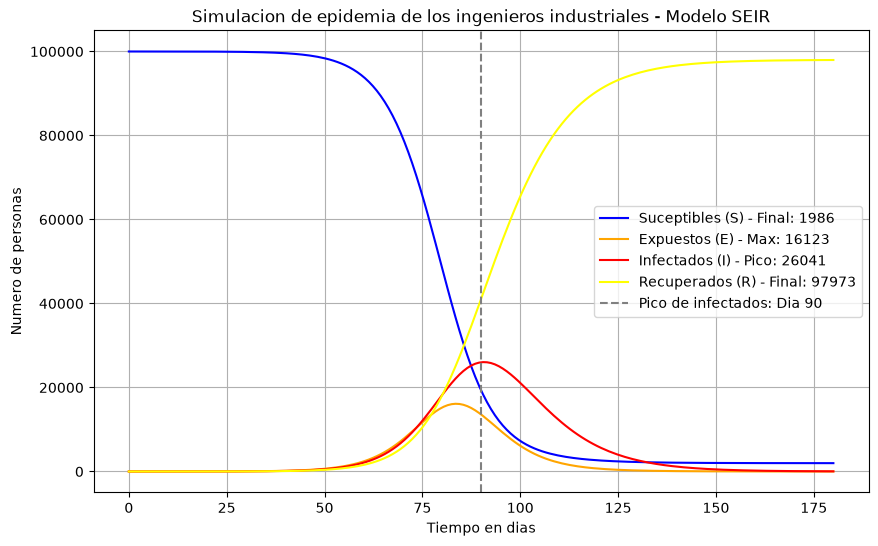

In [116]:
plt.figure(figsize=(10,6))
plt.plot(t, S, label=f"Suceptibles (S) - Final: {int(S[-1])}", color="blue")
plt.plot(t, E, label=f"Expuestos (E) - Max: {int(max(E))}", color="orange")
plt.plot(t, I, label=f"Infectados (I) - Pico: {max_infectados_seir} ", color="red")
plt.plot(t, R, label=f"Recuperados (R) - Final: {int(R[-1])}", color="yellow")
plt.axvline(x=dia_max_infectados_seir, linestyle="--", color="grey", label=f"Pico de infectados: Dia {dia_max_infectados_seir}")
plt.xlabel("Tiempo en dias")
plt.ylabel("Numero de personas")
plt.title("Simulacion de epidemia de los ingenieros industriales - Modelo SEIR")
plt.legend()
plt.grid(True)
plt.show()